In [18]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

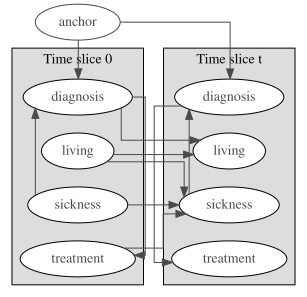

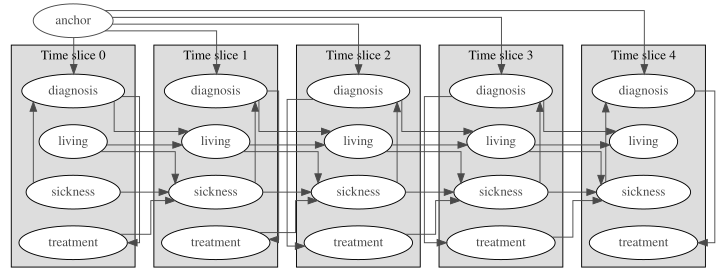

In [59]:
bn2 = gum.loadBN("elder_care_dbn/data/elder_twodbn.bif")
gdyn.showTimeSlices(bn2)

T = 5
dbn2 = gdyn.unroll2TBN(bn2, T)
gdyn.showTimeSlices(dbn2, size="10")

In [47]:
from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

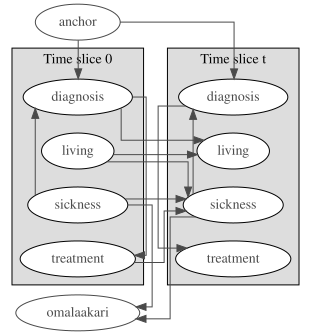

In [82]:
marginals, joint = marginals_and_joint_from_pyagrum(bn2, ["sickness0", "sicknesst"])

cross_impacts = {
    (0, 2): np.array([
        [1, .994141],
        [1, .99],
        [1, 1],
        [.99, 1],
        [.15, 1],
    ]),
    (1, 2): np.array([
        [1, .5],
        [1, .5],
        [1, 1.11],
        [.5, 1],
        [.15, 1],
    ])
}

factors = [
    UncertaintyFactor("sickness0", 5, ()),
    UncertaintyFactor("sicknesst", 5, (0,)),
    UncertaintyFactor("omalaakari", 2, (0, 1)),
]
marginal_omalaakari = np.array([0.1, 0.9])
network = CrossImpactNetwork(
    factors=factors,
    marginals=[marginals[0], marginals[1], marginal_omalaakari],
    cross_impacts=cross_impacts,
)

built=build_network(network, mode="exact", initial_joint=joint)
merged=graft_onto_pyagrum(bn2, built, n_given=2)
gdyn.showTimeSlices(merged)

gnb.sideBySide(merged.cpt("omalaakari"))